# Joint vs R2D2M2 vs stated scales on simulated datasets

TabDGP can draw a dataset's outcome from a generalized linear mixed model (GLMM), whose priors it draws per dataset too.<br>
Independent prior scales would let the linear predictor η grow with every term, until R² nears 1 and the logit and log links saturate.<br>
TabDGP therefore draws the scales jointly, from one budget for the variance of η.<br>
The R2D2M2 prior (the R²-induced Dirichlet decomposition for multilevel models, Aguilar and Bürkner 2023) also spends a budget, but splits it over every coefficient by one Dirichlet.<br>
Real tables fix their design, so only simulated ones show how a scale draw behaves as the design grows.

This experiment checks [how each draw saturates η and splits the explained variance](https://github.com/adkipnis/tabdgp/issues/76) as a grouped table gains columns, grouping factors and random effects.

- **Joint:** τ, the sd of η, drawn per dataset (from R² for a Gaussian y), split between the fixed effects and each grouping factor's random effects, whose scales are set so that each part adds its share.
- **R2D2M2:** R² ~ Beta(2, 2) and one Dirichlet over every slope and random effect, each slope's variance divided by its column's.
- **R2D2M2 on the logit and log links:** y's variance around η linearized at the intercept (Yanchenko, Bondell and Reich 2024).
- **Concentration:** a = 0.5 (`r2d2m2-0.5`) and a = 1 (`r2d2m2-1`) for R2D2M2's Dirichlet.
- **Stated:** the scales of a published model's stated priors, one model per dataset from a survey (`survey`), or every scale at 1 (`unit`), without a budget, as independent scales would be.
- **Shared:** the joint draw's intercept, correlations and families of the fixed effects β and the random effects' sds σ_α.
- **R2D2M2's families:** the joint draw's heavy tails, where its paper has a Normal β and σ_α at its scale.
- **Datasets:** TabDGP's default grouped tables, one size set per cell and the rest drawn.
- **Sizes:** d ∈ {1, 2, 4, 8, 16, 32} design columns besides the intercept, f ∈ {1, 2, 3} grouping factors and q ∈ {1, 3, 6} random effects per factor, its intercept included.
- **Floors:** at least 64 rows across d and at least 5 design columns across q, so that the widest point fits every dataset.
- **Families:** Gaussian, Bernoulli (logit link) and Poisson (log link), 1,000 datasets per cell and family.
- **Ground truth:** every measure is read off the drawn parameters, not off a fit.
- **Saturation:** the share of datasets with some |η| > 10 on the logit, or some Poisson rate above 10⁶.
- **Partition:** the marginal and conditional R² (Nakagawa, Johnson and Schielzeth 2017), the fixed share $R^2_m / R^2_c$ and each grouping factor's intraclass correlation (ICC).
- **Noise on the links:** π²/3 on the logit, ln(1 + 1/λ) on the log link with λ the mean rate over the rows, which MixedBench, a registry of real grouped tables, estimates from a null model.
- **Recorded with each measure:** β's and σ_α's families, τ and the drawn intercept, so a curve can be split by tail or by τ.

`simulated.py` draws the datasets in about 100 s and writes `simulated.csv.gz`; this notebook only reads it.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

plt.rcParams['figure.dpi'] = 72  # smaller inline images, which leaves the vector PDFs alone
records = pd.read_csv('simulated.csv.gz')
print(f'{len(records)} records, {records["index"].nunique()} datasets per cell')

180000 records, 1000 datasets per cell


## Curves

One figure per family, with a row per measure and a column per swept size.<br>
Each line is a draw's median over a cell's datasets, its band the 10-90 % range.<br>
The saturated share has no band, since it is a share of datasets.<br>
A Gaussian y has no link to saturate, so its figure has no such row.

In [2]:
MEASURES = {
    'saturated': 'saturated share',
    'r2_marginal': '$R^2_m$',
    'r2_conditional': '$R^2_c$',
    'fixed_share': '$R^2_m / R^2_c$',
    'icc_1': 'ICC of factor 1',
    'icc_2': 'ICC of factor 2',
    'icc_3': 'ICC of factor 3',
}
FIELD_LABELS = {
    'design_columns': 'd (design columns)',
    'factors': 'f (grouping factors)',
    'random_effects': 'q (random effects per factor)',
}
# three hues (joint, R2D2M2, budget-free), a dashed line for each one's second variant
ARM_STYLES = {
    'joint': {'color': '#2a78d6', 'linestyle': '-'},
    'r2d2m2-0.5': {'color': '#eb6834', 'linestyle': '-'},
    'r2d2m2-1': {'color': '#eb6834', 'linestyle': '--'},
    'survey': {'color': '#1baf7a', 'linestyle': '-'},
    'unit': {'color': '#1baf7a', 'linestyle': '--'},
}


def plotCurves(records: pd.DataFrame, family: str) -> None:
    """One family's measures over each swept size, saved as simulated-<family>.pdf."""
    table = records[records['family'] == family]
    fields = table['field'].unique()  # the swept sizes, in the order simulated.py sweeps them
    measures = []
    for measure in MEASURES:
        if table[measure].notna().any():  # a Gaussian y never saturates
            measures.append(measure)
    figure, axes = plt.subplots(
        len(measures),
        len(fields),
        figsize=(11, 2.1 * len(measures)),
        sharey='row',
        squeeze=False,
        layout='constrained',
    )
    for row, measure in enumerate(measures):
        banded = measure != 'saturated'  # a share of datasets has no band
        for column, field in enumerate(fields):
            ax = axes[row, column]
            swept = table[table['field'] == field]
            values = sorted(swept['value'].unique())
            cells = swept.groupby(['arm', 'value'])[measure]
            if banded:
                center = cells.median()
                low = cells.quantile(0.1)
                high = cells.quantile(0.9)
            else:
                center = cells.mean()
            for arm in table['arm'].unique():
                style = ARM_STYLES[arm]
                # a marker per cell, so a measure with one cell (a third factor's ICC) shows
                ax.plot(center[arm], **style, label=arm, linewidth=2, marker='o', markersize=4)
                if banded:
                    color = style['color']
                    ax.fill_between(low[arm].index, low[arm], high[arm], color=color, alpha=0.12)
            if field == 'design_columns':
                ax.set_xscale('log', base=2)
                ax.set_xticks(values, [str(value) for value in values])
            else:
                ax.set_xticks(values)
            ax.grid(color='#e4e3df', linewidth=0.6)
            ax.spines[['top', 'right']].set_visible(False)
            if row == len(measures) - 1:
                ax.set_xlabel(FIELD_LABELS[field])
            if column == 0:
                ax.set_ylabel(MEASURES[measure])
    handles, labels = axes[0, 0].get_legend_handles_labels()
    figure.legend(handles, labels, loc='outside lower center', ncol=len(labels), frameon=False)
    figure.suptitle(f'{family} y')
    figure.savefig(f'simulated-{family}.pdf', metadata={'CreationDate': None})

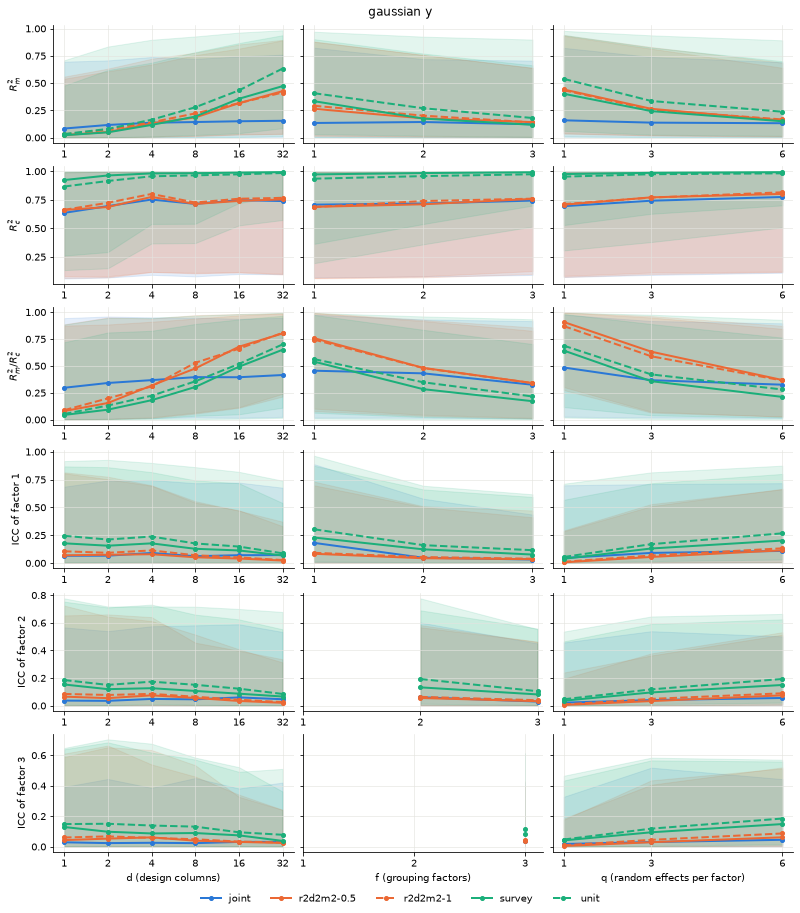

In [3]:
plotCurves(records, 'gaussian')

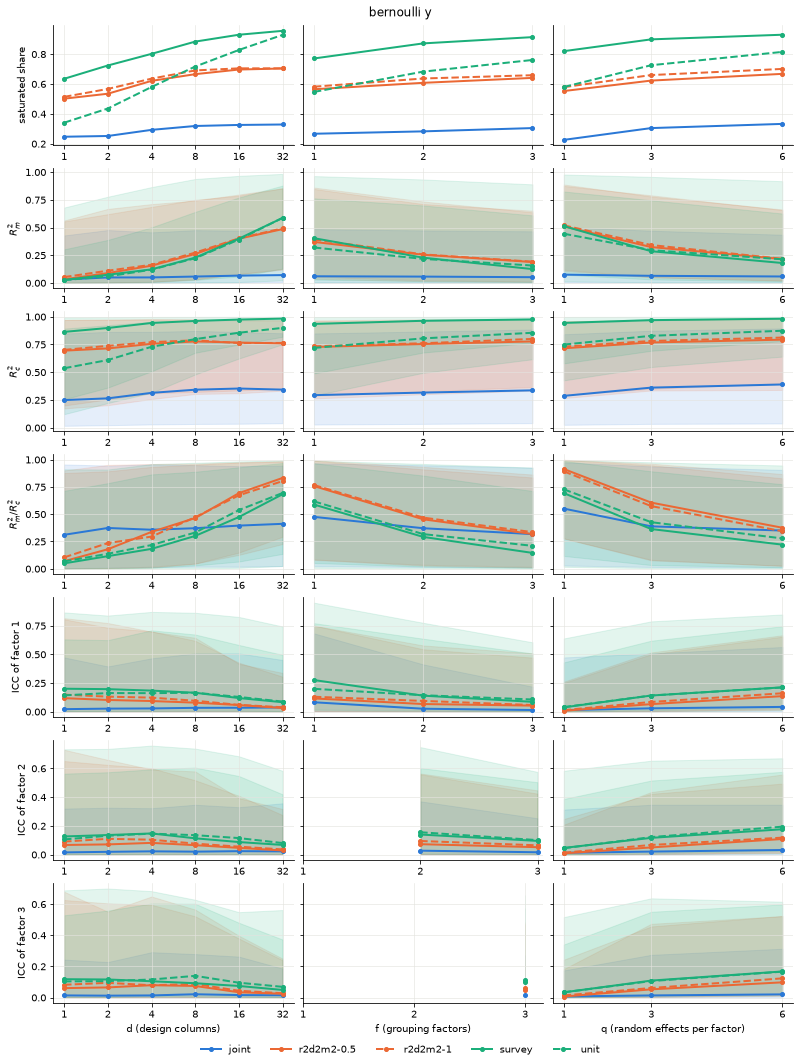

In [4]:
plotCurves(records, 'bernoulli')

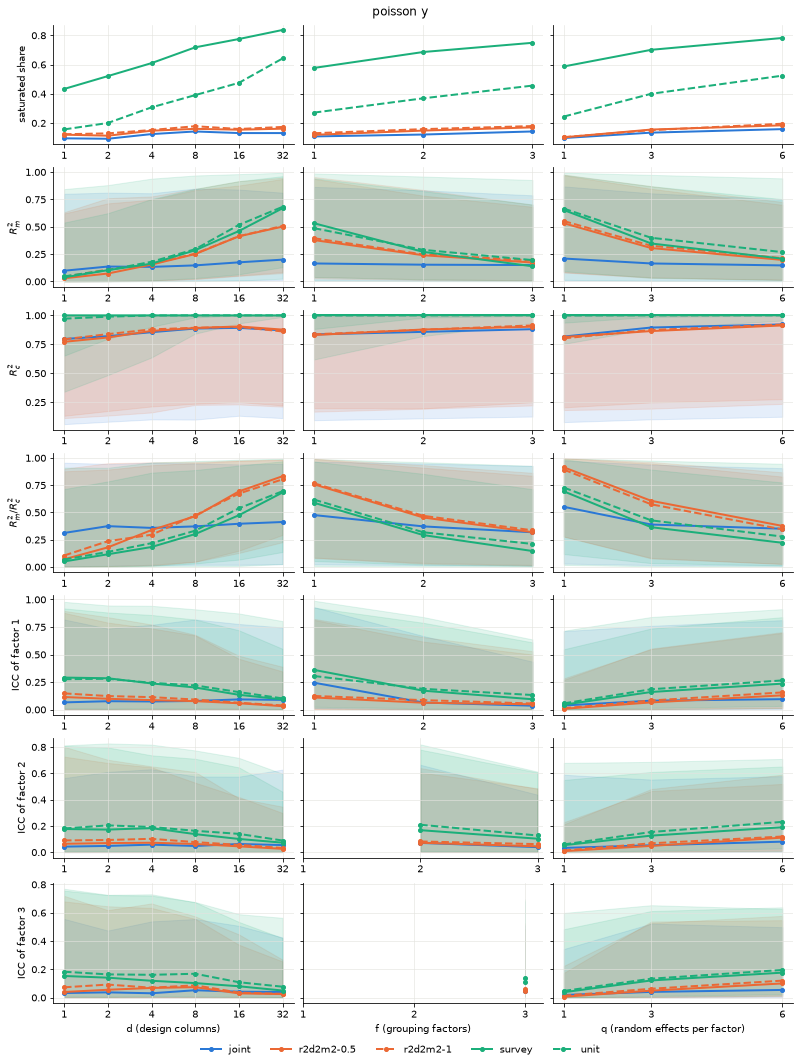

In [5]:
plotCurves(records, 'poisson')

## Read off the records

Two tables the curves cannot show.<br>
The first splits the joint draw's fixed share by tail: all datasets against the light-tailed ones, with a Normal β and a half-normal σ_α.<br>
The second weighs each source of the logit's saturation under the joint draw: how often the prior draws it, how often it saturates and what it adds to the saturated share.

In [6]:
joint = records[records['arm'] == 'joint'].copy()
joint['light'] = (joint['beta_family'] == 'normal') & (joint['sigma_alpha_family'] == 'half_normal')
print(f'{joint["light"].mean():.0%} of the datasets are light-tailed')

# the joint draw's fixed share, its median per cell, under all tails and under light tails
shares = {}
for family in ['gaussian', 'bernoulli']:
    table = joint[joint['family'] == family]
    shares[f'{family}, all'] = table.groupby(['field', 'value'])['fixed_share'].median()
    shares[f'{family}, light'] = (
        table[table['light']].groupby(['field', 'value'])['fixed_share'].median()
    )
with pd.option_context('display.width', 120):
    print(pd.DataFrame(shares).round(2))

# each source of the logit's saturation under the joint draw:
# how often the prior draws it, how often it saturates and what it adds to the saturated share
logit = joint[joint['family'] == 'bernoulli']
saturated = logit['saturated']
sources = {
    'τ > 2': logit['predictor_sd'] > 2,
    '|β₀| > 10': logit['intercept'].abs() > 10,
}
for family in sorted(logit['sigma_alpha_family'].unique()):
    sources[f'σ_α {family}'] = logit['sigma_alpha_family'] == family
for family in sorted(logit['beta_family'].unique()):
    sources[f'β {family}'] = logit['beta_family'] == family
rows = {}
for source, drawn in sources.items():
    rows[source] = {
        'drawn': drawn.mean(),
        'saturated': saturated[drawn].mean(),
        'adds': saturated.mean() - saturated[~drawn].mean(),
    }
baseline = saturated[logit['light'] & (logit['predictor_sd'] <= 2)].mean()
print(f'{saturated.mean():.0%} of the logit datasets saturate')
print(f'{baseline:.0%} of the light-tailed ones with τ <= 2 saturate')
print(pd.DataFrame(rows).T.round(2).to_string())

17% of the datasets are light-tailed
                      gaussian, all  gaussian, light  bernoulli, all  bernoulli, light
field          value                                                                  
design_columns 1               0.30             0.45            0.31              0.49
               2               0.34             0.44            0.37              0.48
               4               0.37             0.52            0.36              0.50
               8               0.40             0.51            0.37              0.50
               16              0.39             0.54            0.40              0.54
               32              0.41             0.56            0.41              0.46
factors        1               0.45             0.51            0.48              0.56
               2               0.43             0.61            0.37              0.47
               3               0.32             0.48            0.32              0.48
random

## Finding

What sets the variance of η under each draw, and what happens to it as the design grows:

| draw | var(η) | as d, f and q grow |
|---|---|---|
| joint | τ per dataset, split by Beta(1, 1) and a Dirichlet over the factors | the budget stays, by construction |
| R2D2M2 | R² per dataset, one Dirichlet over every coefficient | the budget stays, each block's share is its count of terms |
| stated | each coefficient at its stated scale | grows with every term |

**Only the joint draw keeps $R^2_m$ and saturation nearly flat as d grows.**
- **Joint:** $R^2_m$ at most 0.15 on Gaussian and 0.2 on the log link at every d.
- **Joint saturation:** 23-33 % of the logit datasets and 9-16 % of the log-link ones, rising slowly with the count of terms.
- **R2D2M2:** the fixed share is a head count, 0.07 at d = 1 and 0.83 at d = 32 on the logit.
- **R2D2M2 at q = 1:** a lone random intercept vanishes, at a fixed share of 0.87-0.91 against the joint's 0.48-0.55.
- **R2D2M2's logit saturation:** 50-70 %, twice the joint's, since its budget is at least 4 R² / (1 − R²) once y's variance is linearized at the intercept.
- **R2D2M2's log-link saturation:** close to the joint's.
- **Stated saturation:** rises on both links with every column, up to 96 % of the logit datasets at d = 32.
- **Stated $R^2_c$:** runs to 1.
- **Concentration:** a = 0.5 and a = 1 differ by at most 0.06 on any median.

**What the budget leaves open**, off the curves and the first table above.<br>
The budget sets the mean of each block's part of var(η), but a dataset realizes a single draw of it.<br>
A block of k Normal terms realizes a median of about χ²_k's median over k times its budget: 0.45 at k = 1, 0.84 at k = 4 and 0.98 at k = 32.<br>
A heavy-tailed block lands past its budget once its terms add up, since a half-Student-t triples a term's variance, an exponential doubles it and a half-Cauchy has none.<br>
So a dataset's partition follows its count of terms, which the budget ignores:
- **Fixed share:** leans toward the block with more terms, over f from 0.45 to 0.32, over q from 0.48 to 0.32 (on the logit 0.55 to 0.35) and over d up from 0.30 to 0.41.
- **Its drift:** small next to the band Beta(1, 1) draws it in.
- **Under light tails:** higher by about 0.1 in all but one cell.
- **The light-tailed 17 %:** too few datasets per cell to settle a drift of 0.1.
- **Heavy tails:** lower the fixed share, since σ_α's are heavier than β's (a half-Cauchy for a quarter of the σ_α, a Cauchy for 2 % of the β).
- **$R^2_c$:** climbs with the count of terms, over f and q and over most of d.

**What sets the levels**, off the curves and the second table above:
- **The logit's saturation:** mostly τ's upper end, then the half-Cauchy σ_α and an intercept beyond ±10, while β's tails barely add to it.
- **The joint's $R^2_c$ on the logit:** only 0.25-0.39, since τ's median of 1 puts var(η) = 1 against the logit's π²/3.
- **R2D2M2's $R^2_c$ on the logit:** 0.69-0.81, above its own R² ~ Beta(2, 2), since its linearized variance 1 / [p₀ (1 − p₀)] >= 4 exceeds the π²/3 the partition charges.
- **R2D2M2's $R^2_c$ on the log link:** 0.77-0.92, above its Beta(2, 2), since the partition charges ln(1 + 1/λ), less than the 1/λ it budgets at λ = exp(β₀).
- **Both draws' $R^2_c$ on the log link:** lifted further, the joint's to 0.80-0.92, since λ, the mean rate over the rows, exceeds exp(β₀) by Jensen's inequality and through the uncentered 0/1 columns.

**What a scale draw should do**, in plain words, and where the joint draw stands:

| goal | what it asks | the joint draw |
|---|---|---|
| size-free | a table's partition does not depend on d, f or q, unless real tables show that dependence | met by the budget, and by no other draw, though a dataset's partition follows its count of terms |
| honest fields | a drawn fixed share of 0.5 realizes as about 0.5 | missed, short in the block with fewer terms and past it under heavy tails |
| realistic levels | the partition's spread and the saturated share match real grouped tables, link by link | open until the [comparison with MixedBench's registry](https://github.com/adkipnis/tabdgp/issues/77) |
| rare saturation | a saturated logit gives a deterministic y, which teaches a model nothing about the link | missed, since 29 % is high, flat or not |

**Verdict:** the joint draw, whose levels are the open question.<br>
Four defaults of its prior set those levels, and the comparison with real tables decides which to move:
- **τ's top:** log-uniform on 0.25-4 on the links, the logit's main source of saturation.
- **The intercept's scale:** up to 10, which saturates every dataset whose |β₀| exceeds 10.
- **The tails' shares:** a tail heavier than the half-normal's for three quarters of the σ_α, which lowers the fixed share and adds to the saturation.
- **R² instead of τ on the links:** τ² = π²/3 · R² / (1 − R²) with the partition's own noise would put the logit's $R^2_c$ near a median of 0.5, at an sd of η of 1.8 and so more saturation.

The range of τ and the parameterization by R² are one knob seen from two sides, so only one of them moves.<br>
A divisor per tail would remove the heavy tails' overshoot, but not the drift a Normal draw shows too.